# Atividade autoguiada — Afinal, o modelo está bem ajustado?

**Aluna:** Júlia Lima dos Santos

**Disciplina:** Modelagem Estatística de Dados  
**Conteúdos:** Semana 5 — Medidas de qualidade do ajuste; Semana 6 — Diagnóstico do modelo  
**Duração esperada:** aproximadamente 1h45 a 2h  
**Ferramenta:** Google Colab / Python

## Objetivos
Ao final, você deverá ser capaz de:
- ajustar e comparar modelos de regressão linear múltipla;
- interpretar R², R² ajustado e medidas de erro;
- avaliar se maior R² significa, de fato, melhor modelo;
- analisar resíduos;
- verificar linearidade, homocedasticidade, normalidade e independência;
- identificar observações potencialmente influentes;
- reconhecer sinais de sobreajuste (overfitting);
- produzir uma conclusão estatística vinculada a um problema de TI.

> **Importante:** não basta executar as células. Em cada etapa, registre sua interpretação nos espaços indicados.

## Antes de começar
Faça o upload dos arquivos `base_api_latencia.csv` e `base_nuvem_custos.csv` para a pasta **Files** do Colab.  
Os comandos abaixo esperam encontrá-los em `/content/`.

In [1]:
from google.colab import files

uploaded = files.upload()

Saving base_api_latencia.csv to base_api_latencia.csv


In [2]:
from google.colab import files

uploaded = files.upload()

Saving base_nuvem_custos.csv to base_nuvem_custos.csv


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf

from scipy import stats
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.outliers_influence import variance_inflation_factor

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")

def metricas(modelo):
    resid = modelo.resid
    return pd.Series({
        "R2": modelo.rsquared,
        "R2_ajustado": modelo.rsquared_adj,
        "SSE_RSS": np.sum(resid**2),
        "MSE": np.mean(resid**2),
        "RMSE": np.sqrt(np.mean(resid**2)),
        "n_parametros": len(modelo.params)
    })

def diagnostico(modelo):
    bp = het_breuschpagan(modelo.resid, modelo.model.exog)
    sh = stats.shapiro(modelo.resid)
    cook = modelo.get_influence().cooks_distance[0]
    return pd.Series({
        "Shapiro_p": sh.pvalue,
        "Breusch_Pagan_p": bp[1],
        "Durbin_Watson": durbin_watson(modelo.resid),
        "Cook_max": cook.max(),
        "Referencia_4_n": 4/len(modelo.resid)
    })

def graficos_diagnostico(modelo, titulo="Modelo"):
    resid = modelo.resid
    ajust = modelo.fittedvalues
    infl = modelo.get_influence()
    cook = infl.cooks_distance[0]

    fig, ax = plt.subplots(2, 2, figsize=(13, 9))

    ax[0,0].scatter(ajust, resid, alpha=.75)
    ax[0,0].axhline(0, linestyle="--")
    ax[0,0].set_title(f"{titulo}: resíduos × ajustados")
    ax[0,0].set_xlabel("Valores ajustados")
    ax[0,0].set_ylabel("Resíduos")

    sm.qqplot(resid, line="45", ax=ax[0,1])
    ax[0,1].set_title(f"{titulo}: Q-Q plot")

    ax[1,0].hist(resid, bins=14, edgecolor="white")
    ax[1,0].set_title(f"{titulo}: histograma dos resíduos")
    ax[1,0].set_xlabel("Resíduo")

    ax[1,1].vlines(np.arange(len(cook)), 0, cook)
    ax[1,1].axhline(4/len(cook), linestyle="--", label=f"4/n = {4/len(cook):.4f}")
    ax[1,1].set_title(f"{titulo}: distância de Cook")
    ax[1,1].set_xlabel("Índice")
    ax[1,1].legend()

    plt.tight_layout()
    plt.show()

# SITUAÇÃO 1 — O que explica a latência de uma API?

Uma empresa monitora uma API em diferentes períodos de operação. Foram registrados:
- `cpu`: utilização média da CPU (%);
- `memoria`: utilização média da memória (%);
- `requisicoes`: requisições por segundo;
- `conexoes`: conexões simultâneas;
- `cache_hit`: percentual de acertos do cache;
- `latencia`: tempo médio de resposta (ms).

A equipe quer compreender quais características estão associadas à latência.

In [4]:
api = pd.read_csv("/content/base_api_latencia.csv")
api.head()

,id,cpu,memoria,requisicoes,conexoes,cache_hit,latencia
0,1,52.7660,73.4110,592.2350,408.7670,79.0600,57.0670
1,2,65.0850,53.8890,675.1320,523.2880,50.0000,66.5240
2,3,56.7130,48.6120,392.0750,368.2550,77.9380,43.6770
3,4,62.8900,58.2440,505.7520,337.9740,79.1060,44.8680
4,5,58.5340,52.7470,354.5910,400.6710,76.5940,52.8350


## Etapa 1 — Conhecendo os dados

Antes de ajustar um modelo:

1. Identifique a variável resposta.
2. Examine dimensão, tipos e valores ausentes.
3. Calcule estatísticas descritivas.
4. Faça gráficos de dispersão entre `latencia` e cada variável explicativa.
5. Calcule a matriz de correlação.

**Antes de continuar, escreva: quais relações parecem existir? Há variáveis que parecem fornecer informações semelhantes?**

Analisando a matriz de correlação, temos que a CPU é a variável que apresenta a maior correlação com a latência, juntamente ao número de requisições que possui a segunda maior correlação. Já requisições e conexões apresentam uma correlação moderada entre si, o que pode indicar uma sobreposição de informação, mas não prova que existe uma redundância. A memória e o cache hit apresentam relações lineares fracas com a latência. Dessa forma, essas correlações indicam associação, não necessariamente causalidade.


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           150 non-null    int64  
 1   cpu          150 non-null    float64
 2   memoria      150 non-null    float64
 3   requisicoes  150 non-null    float64
 4   conexoes     150 non-null    float64
 5   cache_hit    150 non-null    float64
 6   latencia     150 non-null    float64
dtypes: float64(6), int64(1)
memory usage: 8.3 KB
None


,id,cpu,memoria,requisicoes,conexoes,cache_hit,latencia
count,150.0000,150.0000,150.0000,150.0000,150.0000,150.0000,150.0000
mean,75.5000,59.5835,58.5057,419.2475,321.4811,79.0148,47.8121
std,43.4454,12.6882,9.5482,124.8989,126.0914,8.7653,11.5037
min,1.0000,27.5210,33.3780,100.0000,50.0000,50.0000,16.1540
25%,38.2500,50.3788,52.6562,330.4103,237.3205,73.6270,41.1332
50%,75.5000,59.7170,57.6665,415.4240,321.0545,79.6275,47.3190
75%,112.7500,68.0445,63.8458,498.0627,405.8170,85.9705,55.2125
max,150.0000,92.0000,88.7370,736.1010,650.0000,96.0000,75.2250



Valores ausentes:


,0
id,0
cpu,0
memoria,0
requisicoes,0
conexoes,0
cache_hit,0
latencia,0


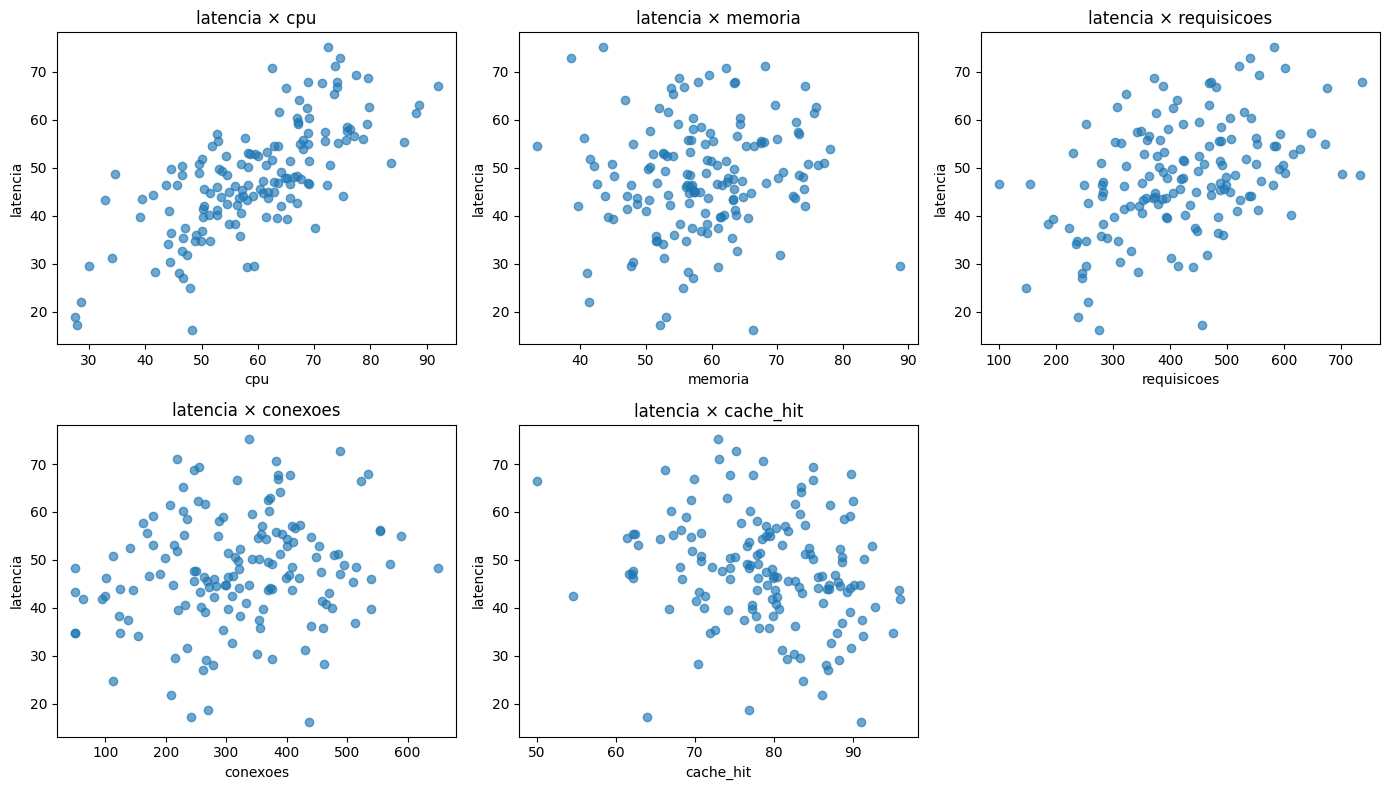


Matriz de correlação:


,cpu,memoria,requisicoes,conexoes,cache_hit,latencia
cpu,1.0000,0.3601,0.0003,-0.0067,-0.1081,0.7135
memoria,0.3601,1.0000,0.0522,0.0666,-0.0034,0.1013
requisicoes,0.0003,0.0522,1.0000,0.5243,-0.1806,0.4285
conexoes,-0.0067,0.0666,0.5243,1.0000,-0.0415,0.1768
cache_hit,-0.1081,-0.0034,-0.1806,-0.0415,1.0000,-0.2205
latencia,0.7135,0.1013,0.4285,0.1768,-0.2205,1.0000


In [5]:
print(api.info())
display(api.describe())
print("\nValores ausentes:")
display(api.isna().sum())

variaveis = ["cpu", "memoria", "requisicoes", "conexoes", "cache_hit"]
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.ravel()
for i, x in enumerate(variaveis):
    axes[i].scatter(api[x], api["latencia"], alpha=.65)
    axes[i].set_xlabel(x)
    axes[i].set_ylabel("latencia")
    axes[i].set_title(f"latencia × {x}")
axes[-1].axis("off")
plt.tight_layout()
plt.show()

print("\nMatriz de correlação:")
display(api[variaveis + ["latencia"]].corr())

### Sua análise — Etapa 1
**Variável resposta:**  Latência.

**Relações que parecem mais importantes:**  A CPU e o número de requisições com a latência, já que essas relações apresentam a maior correlação positiva. Então, acredito que essas variáveis tenham maior importância na explicação da latência.

**Possíveis redundâncias entre explicativas:**  Requisições e conexões apresentam correlação positiva moderada (0,5243). Sendo assim, elas podem fornecer informações semelhantes.

**O que você espera encontrar no primeiro modelo?** Espero que a CPU e o número de requisições sejam estatisticamente significativos e ajudem a explicar a latência.

## Etapa 2 — Primeiro modelo

Ajuste:

\[
Latencia_i = \beta_0 + \beta_1 CPU_i + \beta_2 Memoria_i +
\beta_3 Requisicoes_i + \varepsilon_i
\]

Analise R², R² ajustado, teste F, coeficientes, p-valores e intervalos de confiança.

In [6]:
modelo1 = smf.ols("latencia ~ cpu + memoria + requisicoes", data=api).fit()
print(modelo1.summary())

                            OLS Regression Results                            
Dep. Variable:               latencia   R-squared:                       0.729
Model:                            OLS   Adj. R-squared:                  0.723
Method:                 Least Squares   F-statistic:                     130.9
Date:                Tue, 13 Oct 2026   Prob (F-statistic):           3.33e-41
Time:                        15:14:27   Log-Likelihood:                -480.81
No. Observations:                 150   AIC:                             969.6
Df Residuals:                     146   BIC:                             981.7
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept       2.7947      3.683      0.759      

### Sua análise — Etapa 2
**1. Quanto da variabilidade observada da latência é explicada pelo modelo?**

O modelo explica 72,9% da variação da latência, pois R²=0,729. Isso significa que as variáveis CPU, memória e requisições conseguem explicar boa parte das diferenças na latência.

**2. O modelo é globalmente significativo? Como você sabe?**

Sim. O teste F apresenta p-valor de 3.33e-41 (3.33 × 10⁻⁴¹), que é menor do que 0,05. Isso mostra que o modelo é significativo como um todo e que pelo menos uma das variáveis explicativas pode ser usada para explicar a latência.

**3. Quais variáveis apresentam evidência de associação com a latência?**

As três variáveis: CPU, memória e requisições apresentam evidências de que são associadas com a latência, pois seus p-valores são menores do que 0,05. Com isso, todas são estatisticamente significativas no modelo.

**4. Interprete os sinais e os coeficientes, mantendo as demais variáveis constantes.**

A CPU possui coeficiente positivo de 0,7137, indicando que o aumento de uma unidade na CPU está relacionado a um aumento médio de 0,7137 na latência. As requisições também possuem coeficiente positivo, de 0,0404, ou seja, cada unidade a mais está associada a um aumento médio de 0,0404 na latência. Já a memória possui coeficiente negativo de -0,2472, indicando que o aumento de uma unidade na memória está relacionado a uma redução de 0,2472 na latência, mantendo as outras variáveis constantes.

**5. É possível concluir causalidade? Por quê?**

Não. O modelo mostra associações entre as variáveis, mas isso não significa que uma variável cause mudanças na latência de maneira direta. Outros fatores podem influenciar os resultados, e seria necessário realizar outras análises para investigar uma relação de causa e efeito.

## Etapa 3 — Mais variáveis sempre melhoram o modelo?

Inclua `conexoes` e compare os dois ajustes.

In [7]:
modelo2 = smf.ols("latencia ~ cpu + memoria + requisicoes + conexoes", data=api).fit()

comparacao = pd.DataFrame({
    "Modelo 1": metricas(modelo1),
    "Modelo 2": metricas(modelo2)
})
display(comparacao)
print(modelo2.summary())

,Modelo 1,Modelo 2
R2,0.7290,0.7307
R2_ajustado,0.7235,0.7232
SSE_RSS,5343.1601,5311.0279
MSE,35.6211,35.4069
RMSE,5.9683,5.9504
n_parametros,4.0000,5.0000


                            OLS Regression Results                            
Dep. Variable:               latencia   R-squared:                       0.731
Model:                            OLS   Adj. R-squared:                  0.723
Method:                 Least Squares   F-statistic:                     98.33
Date:                Tue, 13 Oct 2026   Prob (F-statistic):           2.69e-40
Time:                        15:14:27   Log-Likelihood:                -480.36
No. Observations:                 150   AIC:                             970.7
Df Residuals:                     145   BIC:                             985.8
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept       3.1318      3.702      0.846      

### Sua análise — Etapa 3
**1. Qual modelo tem maior R²?**

O modelo 2 tem o maior R², com 0,7307, já o modelo 1 tem R²=0,7290. Porém, a diferença é muito pequena, logo, podemos concluir que adicionar a variável conexões aumentou pouco a capacidade de explicação do modelo.

**2. O R² ajustado conduz à mesma conclusão?**

Não. O modelo 1 possui R² ajustado de 0,7235, um pouco maior que o do modelo 2, que é de 0,7232. Isso mostra que incluir a variável "conexões" não trouxe uma melhoria relevante.

**3. O RMSE diminuiu de maneira relevante?**  

Não. O modelo 1 possui o RMSE de 5,9683 e o modelo 2 possui o RMSE de 5,9504. Essa diminuição é muito pequena, indicando que o erro de previsão mudou muito pouco com a inclusão de "conexões".

**4. `conexoes` contribuiu de forma convincente?**

Não. A variável "conexões" apresenta p-valor de 0,351, maior do que 0,05, o que indica que não há evidências estatísticas suficientes de uma associação com a latência, considerando as outras variáveis. Além disso, seu coeficiente é pequeno e negativo com o valor de -0,0043.

**5. Qual modelo você escolheria? Justifique usando mais de uma medida.**

Eu escolheria o modelo 1, visto que possui um R² praticamente igual ao do modelo 2 e um R² ajustado e um RMSE com valores muito próximos. Além disso, a variável "conexões" não apresentou significância estatística. Sendo assim, o modelo 1 é mais simples e mantém quase o mesmo desempenho, sem incluir uma variável que não demonstrou grande contribuição.

### Pare e pense
**Se acrescentássemos várias variáveis pouco úteis, o que tenderia a acontecer com o R²? E com o R² ajustado?**

Existiriam duas opções para o R², que são aumentar ou permanecer igual, mesmo acrescentando variáveis pouco úteis, pois ele não diminui quando novas variáveis explicativas são adicionadas ao modelo. Já o R² ajustado poderia diminuir, uma vez que considera a quantidade de variáveis que são adicionadas. Portanto, acrescentar muitas variáveis que não são úteis pode aumentar o R² sem melhorar de fato o modelo. Logo, é importante dar atenção ao R² ajustado para evitar incluir variáveis que não são relevantes e necessárias.

## Etapa 4 — Um bom R² encerra a análise?

Agora avalie os resíduos do **Modelo 1**. Primeiro faça uma avaliação visual.

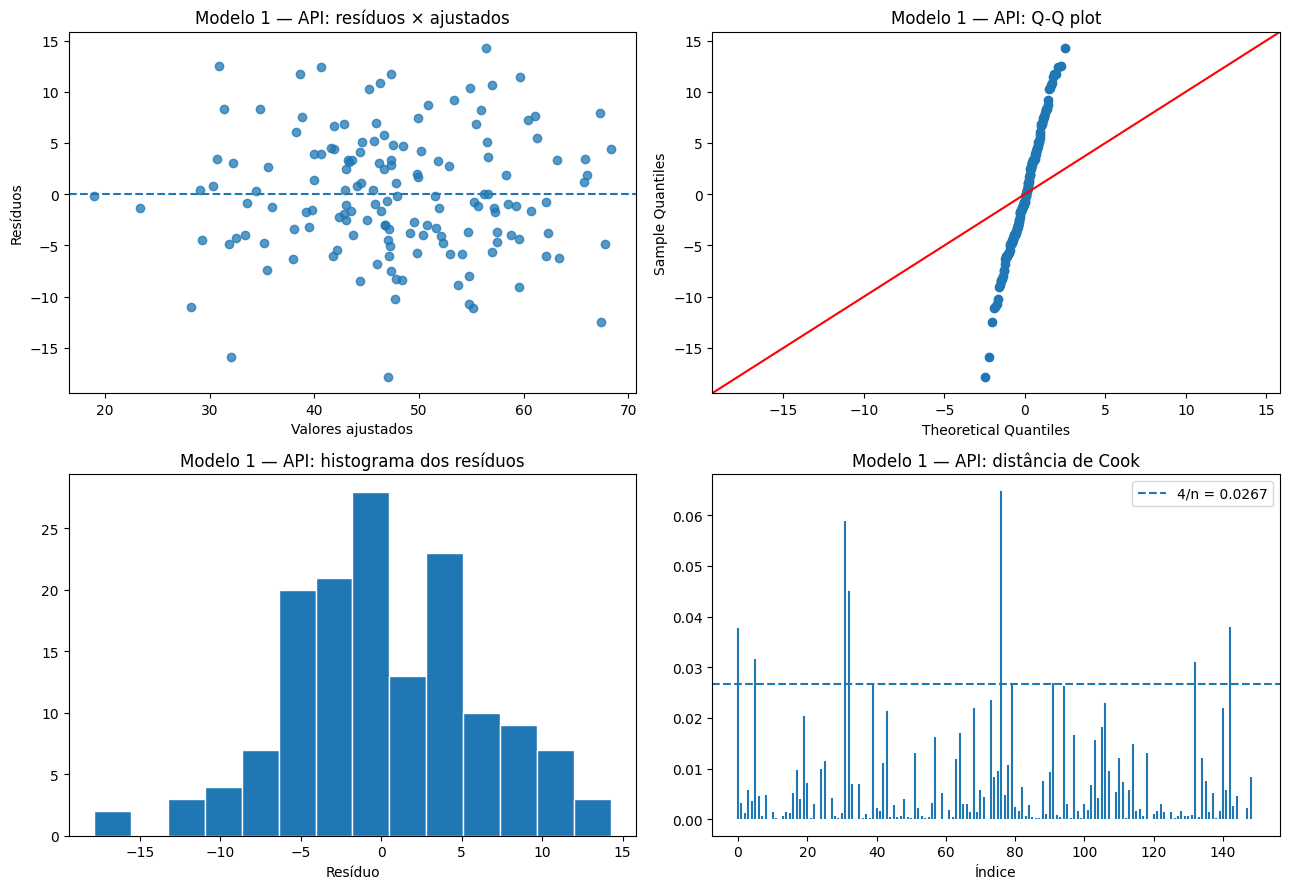

In [8]:
graficos_diagnostico(modelo1, "Modelo 1 — API")

### Avaliação visual
- **Os resíduos estão aproximadamente centrados em zero?**

Sim. Os resíduos estão distribuídos em torno da linha zero, com valores positivos e negativos, indicando que os erros não parecem estar concentrados apenas em um lado.

- **Existe curvatura?**

Não possui uma curvatura evidente no gráfico, pois os pontos estão distribuídos sem formar um padrão de curva.

- **A dispersão parece aproximadamente constante?**

Sim, a dispersão parece constante, pois não existe um formato de funil muito evidente no gráfico. Ainda assim, seria necessário fazer um teste para confirmar.

- **O Q-Q plot apresenta afastamentos importantes?**

Sim, principalmente nas extremidades, onde os pontos se afastam bastante da linha vermelha. Isso pode indicar que os resíduos não seguem uma distribuição normal.

- **Há observações que merecem atenção no gráfico de Cook?**

Sim, algumas observações ultrapassam a linha tracejada. Essas observações podem ter influência nos resultados do modelo e merecem ser analisadas melhor.

Registre sua avaliação **antes** de executar os testes formais.

## Etapa 5 — Diagnóstico formal

Use:
- Shapiro-Wilk para normalidade;
- Breusch-Pagan para homocedasticidade;
- Durbin-Watson para autocorrelação de primeira ordem, quando a ordem das observações fizer sentido.

Lembre-se: `p > 0,05` **não prova** a hipótese nula.

In [9]:
display(diagnostico(modelo1))

,0
Shapiro_p,0.6463
Breusch_Pagan_p,0.7998
Durbin_Watson,2.0559
Cook_max,0.0648
Referencia_4_n,0.0267


### Sua análise — Etapa 5
**Normalidade:**  O teste de Shapiro possui p-valor de 0,6463, maior do que 0,05. Portanto, não há muitas evidências para afirmar que os resíduos não seguem uma distribuição normal.

**Homocedasticidade:**  O teste de Breusch-Pagan possui p-valor de 0,7998, maior do que 0,05. Isso mostra que não existe evidências de que a variação dos erros seja diferente ao longo dos valores previstos pelo modelo. Portanto, os erros parecem ter uma dispersão constante, o que vai de acordo com a presença da homocedasticidade.

**Independência:**  O valor de Durbin-Watson é 2,0559, próximo de 2. Isso indica que não existem evidências importantes de autocorrelação dos resíduos.

**As conclusões dos testes são coerentes com os gráficos?**

São coerentes em partes. No gráfico Q-Q, os pontos apresentam afastamentos da linha nas extremidades, mas o teste de Shapiro não indica grandes problemas de normalidade. No gráfico de resíduos x valores ajustados, não existe um padrão de dispersão irregular, o que faz sentido com o resultado do teste de Breusch-Pagan. Já o gráfico de Cook mostra algumas observações acima do valor de referência de 4/n, que é 0,0267, indicando que elas merecem ser investigadas, pois podem ter uma influência relevante no modelo.

## Etapa 6 — Observações potencialmente influentes

Use resíduos studentizados, leverage e Distância de Cook.  
A referência `4/n` será usada apenas como **sinal para investigação**, e não como regra automática de exclusão.

In [10]:
infl = modelo1.get_influence()
diag_obs = pd.DataFrame({
    "id": api["id"],
    "resid_student": infl.resid_studentized_external,
    "leverage": infl.hat_matrix_diag,
    "cook": infl.cooks_distance[0]
})

limite = 4/len(api)
suspeitas = diag_obs[diag_obs["cook"] > limite].sort_values("cook", ascending=False)
print(f"Referência 4/n = {limite:.4f}")
display(suspeitas)

Referência 4/n = 0.0267


,id,resid_student,leverage,cook
76,77,-2.1435,0.0547,0.0648
31,32,-2.7226,0.0321,0.0588
32,33,-1.8741,0.0496,0.0451
142,143,2.1279,0.0332,0.0380
0,1,1.8420,0.0434,0.0378
5,6,2.4203,0.0219,0.0317
132,133,1.9833,0.0311,0.0309
39,40,1.3472,0.0563,0.0269
91,92,1.5651,0.0424,0.0269


### Investigação
**1. Quantas observações ultrapassam a referência?**

São 9. As observações que passaram são: 77, 32, 33, 143, 1, 6, 133, 40 e 92.

**2. Isso significa que devem ser excluídas?**

Não. Ultrapassar a referência de 4/n não significa a observação deva ser excluída. Essa referência serve somente como um sinal de alerta.

**3. Escolha a observação de maior Cook e faça uma análise de sensibilidade.**

A observação escolhida é a de id 77, que apresenta a maior distância de Cook, de 0,0648.

In [11]:
idx_maior = diag_obs["cook"].idxmax()
id_maior = int(api.loc[idx_maior, "id"])
print("ID com maior Cook:", id_maior)

api_sem = api.drop(index=idx_maior)
modelo1_sem = smf.ols("latencia ~ cpu + memoria + requisicoes", data=api_sem).fit()

comparacao_sens = pd.DataFrame({
    "Completo": modelo1.params,
    "Sem maior Cook": modelo1_sem.params
})
display(comparacao_sens)
print("\nR² ajustado completo:", modelo1.rsquared_adj)
print("R² ajustado sem o ponto:", modelo1_sem.rsquared_adj)

ID com maior Cook: 77


,Completo,Sem maior Cook
Intercept,2.7947,2.6147
cpu,0.7137,0.7232
memoria,-0.2472,-0.2629
requisicoes,0.0404,0.0419



R² ajustado completo: 0.7234543868758085
R² ajustado sem o ponto: 0.7312225060848501


### Sua conclusão — influência
**A retirada temporária mudou substancialmente coeficientes ou conclusão?**

Remover a observação 77 causou pequenas mudanças nos coeficientes. A CPU passou de 0,7137 para 0,7232, a memória passou de -0,2472 para -0,2629 e as requisições passaram de 0,0404 para 0,0419. O R² ajustado aumentou de 0,7235 para 0,7312. Portanto, houve uma pequena melhora no ajuste do modelo, mas os coeficientes continuaram com os mesmos sinais. Sendo assim, isso indica que a observação influencia os resultados, mas não muda a interpretação geral dessas variáveis.

**O que você faria com essa observação em uma análise real?**

Como a retirada causou mudanças pequenas nos coeficientes e melhorou um pouco o R² ajustado, não excluiria essa observação automaticamente. Se os dados estivessem corretos, eu manteria a observação e apresentaria a comparação dos dois modelos, explicando que sua presença influencia um pouco os resultados.

# SITUAÇÃO 2 — Quando um ótimo ajuste esconde problemas

Uma plataforma em nuvem quer explicar seu custo operacional diário a partir de:
- `usuarios`: usuários ativos;
- `trafego`: volume de tráfego;
- `armazenamento`: armazenamento utilizado;
- `incidentes`: incidentes registrados;
- `custo`: custo operacional.

Agora você deverá repetir o raciocínio anterior com **menos orientação**.

In [12]:
nuvem = pd.read_csv("/content/base_nuvem_custos.csv")
display(nuvem.head())
display(nuvem.describe())

,id,usuarios,trafego,armazenamento,incidentes,custo
0,1,9418.2740,630.6870,597.0700,5,1817.4830
1,2,6069.3620,244.7990,715.4710,7,1279.3780
2,3,10413.0430,551.8940,770.7350,6,1818.2050
3,4,9466.9260,619.4160,758.4940,2,1569.1950
4,5,2525.9810,259.8010,154.6820,0,668.6320


,id,usuarios,trafego,armazenamento,incidentes,custo
count,140.0000,140.0000,140.0000,140.0000,140.0000,140.0000
mean,70.5000,6873.5873,459.3490,824.0855,3.6500,1525.0438
std,40.5586,3365.5479,167.2123,434.4479,2.0460,588.4357
min,1.0000,893.0890,83.3780,102.6470,0.0000,579.0360
25%,35.7500,3896.3112,323.6377,414.4692,2.0000,973.0833
50%,70.5000,7098.9290,462.9110,809.8675,3.0000,1454.3640
75%,105.2500,9908.8202,597.8915,1187.6553,5.0000,2027.8155
max,140.0000,11994.5940,776.3460,1598.5250,10.0000,2845.4700


## Etapa 7 — Ajuste inicial

Ajuste:

\[
Custo_i = \beta_0 + \beta_1 Usuarios_i + \beta_2 Trafego_i +
\beta_3 Armazenamento_i + \beta_4 Incidentes_i + \varepsilon_i
\]

Antes dos diagnósticos, responda:

**- O modelo parece bom pela saída de regressão?**

Sim. O modelo apresenta um bom ajuste geral. O teste F possui p-valor menor do que 0,05 (1.80e-65), indicando que o modelo é estatisticamente significativo no geral.

**- Quanto ele explica?**

O R²=0,8967 mostra que 89,67% da variação do custo operacional é explicada pelas variáveis presentes no modelo. Já o R² ajustado é de 89,36%, mostrando que o bom ajuste continua mesmo considerando o número de variáveis usadas.

**- Quais variáveis parecem relevantes?**

Usuários, tráfego e armazenamento são variáveis que apresentam evidências de associação com o custo operacional. Já incidentes não é estatisticamente significativa, pois seu p-valor é maior do que 0,05.

**- Você já o recomendaria?**

Não, pois, apesar do bom ajuste e da significância geral, é necessário realizar os diagnósticos dos resíduos para verificar possíveis problemas, como heterocedasticidade, falta de normalidade, autocorrelação e observações influentes.

In [13]:
modelo_custo = smf.ols(
    "custo ~ usuarios + trafego + armazenamento + incidentes",
    data=nuvem
).fit()

print(modelo_custo.summary())
display(metricas(modelo_custo))

                            OLS Regression Results                            
Dep. Variable:                  custo   R-squared:                       0.897
Model:                            OLS   Adj. R-squared:                  0.894
Method:                 Least Squares   F-statistic:                     292.8
Date:                Tue, 13 Oct 2026   Prob (F-statistic):           1.80e-65
Time:                        15:14:28   Log-Likelihood:                -932.12
No. Observations:                 140   AIC:                             1874.
Df Residuals:                     135   BIC:                             1889.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept       176.6350     57.712      3.061

,0
R2,0.8967
R2_ajustado,0.8936
SSE_RSS,4974145.1829
MSE,35529.6084
RMSE,188.4930
n_parametros,5.0000


## Etapa 8 — Descubra o que o resumo da regressão não mostrou

Faça os diagnósticos visual e formal.

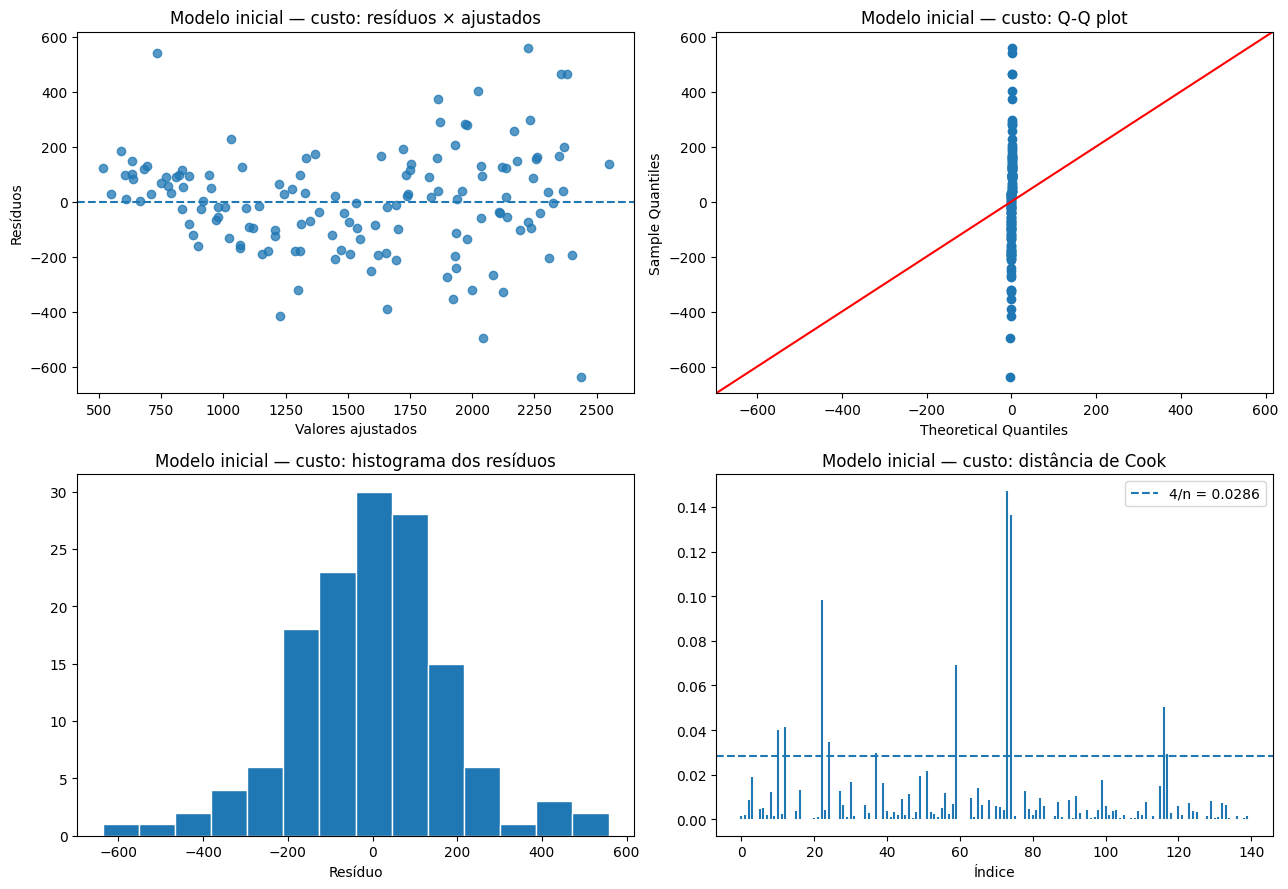

,0
Shapiro_p,0.0477
Breusch_Pagan_p,0.0035
Durbin_Watson,2.4451
Cook_max,0.1472
Referencia_4_n,0.0286


In [14]:
graficos_diagnostico(modelo_custo, "Modelo inicial — custo")
display(diagnostico(modelo_custo))

### Complete o diagnóstico

| Aspecto | Evidência usada | Sua conclusão |
|---|---|---|
| Qualidade do ajuste | R² / R² ajustado / RMSE |O modelo explica 89,67% da variação do custo, indicando bom poder explicativo. O erro típico de previsão, medido pelo RMSE, é de 188,49 unidades de custo. |
| Linearidade | resíduos × ajustados | Os resíduos apresentam dispersão ao redor de zero, mas há indícios de um padrão curvo, com resíduos mais negativos no centro e mais positivos em outras regiões. Isso pode indicar que a relação linear não representa completamente os dados. |
| Homocedasticidade | gráfico + Breusch-Pagan | O teste apresenta p-valor menor do que 0,05, indicando evidências de heterocedasticidade. Portanto, a variância dos resíduos não parece constante. |
| Normalidade | Q-Q + Shapiro-Wilk | O teste de Shapiro-Wilk apresenta p-valor menor do que 0,05, indicando que os resíduos não seguem uma distribuição normal. O histograma também mostra valores extremos, ou seja, existe a necessidade de investigar os resíduos.|
| Independência | Durbin-Watson | O valor está próximo de 2, mas um pouco acima, o que pode indicar uma autocorrelação negativa. É necessário considerar a ordem das observações e realizar outra avaliação antes de concluir se existe dependência dos resíduos. |
| Influência | Cook | Existem observações com distância de Cook acima da referência, com algumas muito altas (entre os indíces 70 e 80). Essas observações podem ter influência sobre os coeficientes e devem ser investigadas.|

**Pergunta central:** o modelo é adequado apenas porque apresenta R² elevado e teste F significativo?

Não. Apenas esses valores não garantem que o modelo seja adequado. O R² elevado indica que o modelo explica grande parte da variação do custo, já o teste F significativo indica que o modelo é estatisticamente significativo como um todo. No entanto, os diagnósticos indicam evidências de heterocedasticidade, desvio da normalidade dos resíduos e observações potencialmente influentes. Além disso, vale investigar a possível falta de linearidade e a independência dos erros. Portanto, é preciso analisar as observações influentes, verificar relações não lineares e considerar erros-padrão robustos para lidar com a heterocedasticidade.

## Etapa 9 — Tente melhorar o modelo

Proponha **uma modificação fundamentada**. Exemplos possíveis:
- termo quadrático;
- interação;
- transformação;
- retirada de variável redundante;
- outra reespecificação justificável.

Não escolha uma alteração apenas para aumentar o R². Explique primeiro **qual problema você pretende tratar**.

A célula abaixo apresenta uma possibilidade com termo quadrático para `usuarios`. Você pode usá-la ou propor outra.

,Original,Modificado
R2,0.8967,0.9094
R2_ajustado,0.8936,0.9060
SSE_RSS,4974145.1829,4360249.5952
MSE,35529.6084,31144.6400
RMSE,188.4930,176.4784
n_parametros,5.0000,6.0000



Diagnóstico do modelo modificado:


,0
Shapiro_p,0.0031
Breusch_Pagan_p,0.0010
Durbin_Watson,2.3950
Cook_max,0.2091
Referencia_4_n,0.0286


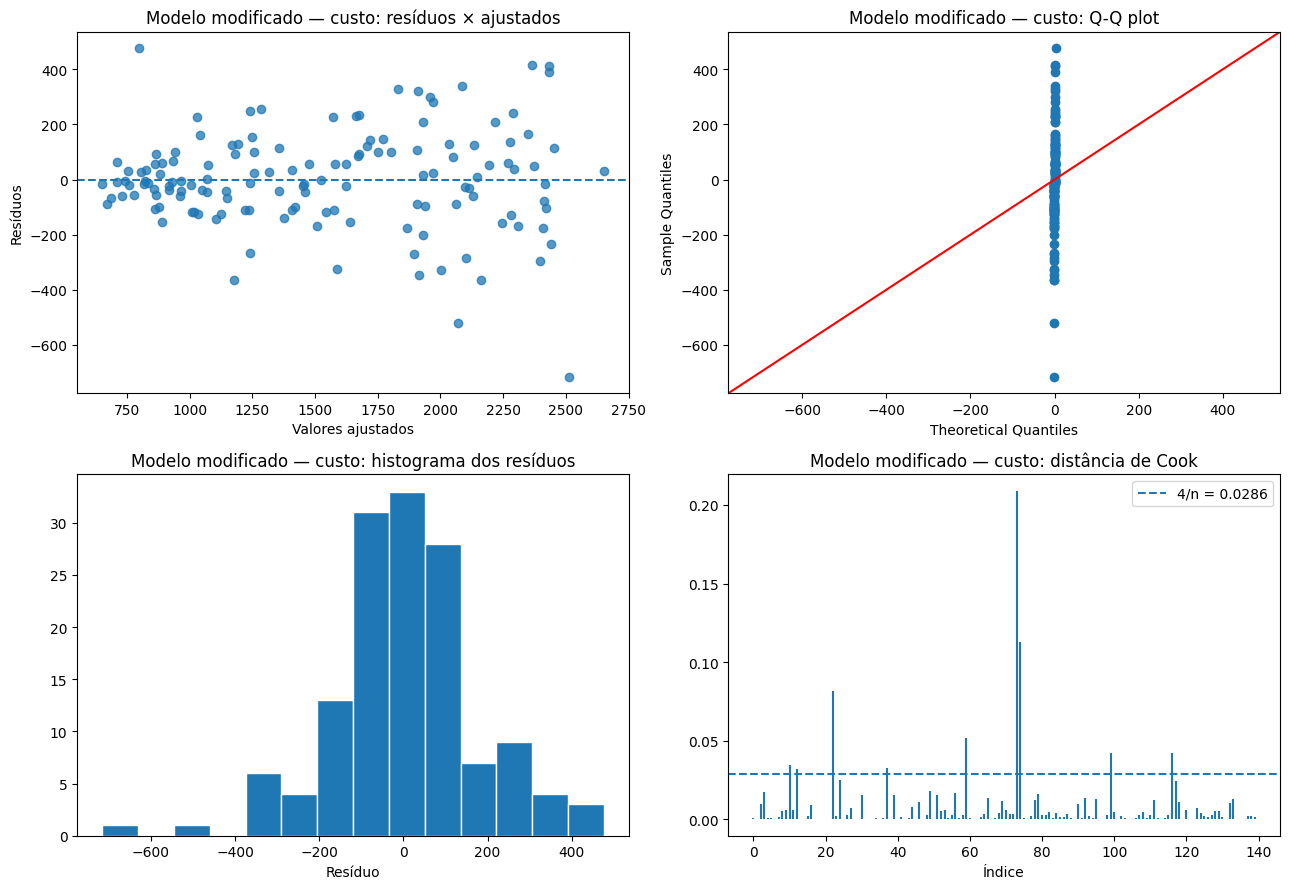

In [15]:
modelo_custo_mod = smf.ols(
    "custo ~ usuarios + I(usuarios**2) + trafego + armazenamento + incidentes",
    data=nuvem
).fit()

comparacao_custo = pd.DataFrame({
    "Original": metricas(modelo_custo),
    "Modificado": metricas(modelo_custo_mod)
})
display(comparacao_custo)

print("\nDiagnóstico do modelo modificado:")
display(diagnostico(modelo_custo_mod))
graficos_diagnostico(modelo_custo_mod, "Modelo modificado — custo")

### Sua análise — Etapa 9
**1. O termo adicional melhorou R² ajustado e RMSE?**

Sim. O R² ajustado aumentou de 0,8936 para 0,9060, já o RMSE diminuiu de 188,49 para 176,48. Isso indica que houve melhora no ajuste e na redução do erro de previsão dentro da amostra.

**2. O padrão de curvatura melhorou?**

O termo quadrático pode ter ajudado a representar uma relação não linear, mas o gráfico de resíduos ainda mostra uma dispersão desigual e alguns possíveis padrões. Portanto, não é possível afirmar que o padrão da curvatura melhorou.

**3. A heterocedasticidade desapareceu?**

Não. O teste de Breusch-Pagan possui p=0,0010, menor do que 0,05. Logo, existem evidências de que a variância dos resíduos não é constante.

**4. A normalidade melhorou?**

A normalidade não melhorou o suficiente, pois o teste de Shapiro-Wilk apresentou p-valor=0,0031, menor do que 0,05. Isso indica que os resíduos ainda não seguem uma distribuição normal.

**5. Surgiram ou permaneceram observações influentes?**

Permaneceram observações potencialmente influentes. A distância de Cook máxima aumentou de 0,1472 para 0,2091, e vários pontos ultrapassam a referência 4/n=0,0286. Essas observações devem ser investigadas.

**6. O modelo modificado é realmente melhor, ou apenas possui R² maior?**

O modelo modificado teve resultados melhores, com o R² ajustado maior e o RMSE menor, indicando que ele explica melhor os dados e apresenta erros menores. No entanto, ainda existem problemas nos diagnósticos, então não podemos afirmar que ele é totalmente adequado.

> Uma única modificação não precisa resolver todos os problemas. Saber reconhecer isso faz parte do diagnóstico.

## Etapa 10 — Experimento de complexidade e overfitting

Volte à base da API e ajuste modelos progressivamente mais complexos.

- A: apenas `cpu`;
- B: `cpu + memoria + requisicoes`;
- C: todas as variáveis explicativas disponíveis;
- D: todas as variáveis + termos quadráticos + interações selecionadas.

Compare R², R² ajustado e RMSE **nos próprios dados de ajuste** e discuta a parcimônia.  
Nesta disciplina, o objetivo aqui não é fazer divisão treino/teste, mas observar como métricas de ajuste respondem à complexidade.

In [16]:
mA = smf.ols("latencia ~ cpu", data=api).fit()
mB = smf.ols("latencia ~ cpu + memoria + requisicoes", data=api).fit()
mC = smf.ols("latencia ~ cpu + memoria + requisicoes + conexoes + cache_hit", data=api).fit()
mD = smf.ols(
    "latencia ~ cpu + memoria + requisicoes + conexoes + cache_hit"
    " + I(cpu**2) + I(memoria**2) + I(requisicoes**2)"
    " + cpu:requisicoes + memoria:requisicoes + conexoes:cache_hit",
    data=api
).fit()

tabela_complexidade = pd.DataFrame({
    "A": metricas(mA),
    "B": metricas(mB),
    "C": metricas(mC),
    "D": metricas(mD)
}).T

display(tabela_complexidade[["R2","R2_ajustado","RMSE","n_parametros"]])

,R2,R2_ajustado,RMSE,n_parametros
A,0.5091,0.5058,8.0333,2.0000
B,0.7290,0.7235,5.9683,4.0000
C,0.7338,0.7245,5.9159,6.0000
D,0.7415,0.7208,5.8299,12.0000


### Sua análise — Etapa 10
**- O que aconteceu com o R² à medida que a complexidade aumentou?**

O R² aumentou de 0,5091 no modelo A para 0,7415 no modelo D. Isso mostra que os modelos mais complexos conseguiram explicar uma parte maior da variação da latência da API.

**- O R² ajustado teve o mesmo comportamento?**

Não. O R² ajustado aumentou até o modelo C, mas diminuiu no modelo D. Isso indica que a inclusão de mais parâmetros no último modelo não trouxe uma melhora suficiente para compensar sua complexidade.

**- O ganho de RMSE justificou todos os parâmetros adicionais?**

Não necessariamente. O RMSE diminuiu de 5,9159 no modelo C para 5,8299 no modelo D, uma melhora pequena, já que o número de parâmetros dobrou, passando de 6 para 12.

**- Qual modelo parece oferecer melhor equilíbrio entre ajuste e parcimônia?**

O modelo C, pois apresenta um bom ajuste e um erro baixo sem precisar de tantos parâmetros quanto o modelo D. Assim, ele oferece um equilíbrio melhor entre explicar os dados e manter o modelo mais simples.

**- Onde aparece o risco de overfitting?**

O risco aparece muito no modelo D, porque ele possui mais variáveis, termos quadráticos e interações. Como as métricas foram calculadas nos próprios dados de ajuste, o modelo pode estar se adaptando demais a esses dados, sem conseguir apresentar o mesmo desempenho em outras situações.

# Produto final — Parecer técnico

Escreva um texto de **15 a 20 linhas**, sem tópicos, respondendo:

> Com base nas duas situações, explique por que a avaliação de um modelo de regressão não pode ser realizada apenas pelo R². Utilize evidências obtidas na atividade e discuta qualidade do ajuste, complexidade, resíduos, pressupostos e influência das observações. Finalize explicando quais elementos você consideraria antes de recomendar um modelo para apoiar uma decisão na área de TI.

### Seu parecer

A avaliação de um modelo de regressão não pode considerar apenas o R², pois ele mostra quanto da variação dos dados é explicada pelo modelo, mas não garante que ele seja adequado. Na análise da API, por exemplo, o modelo inicial apresentou R² de 0,729, indicando um bom poder explicativo. No entanto, foi necessário avaliar os resíduos para verificar se os pressupostos da regressão eram atendidos. Os testes identificaram problemas como heterocedasticidade e observações influentes que precisavam ser investigadas. Na análise do custo operacional, o modelo inicial apresentou R² de 0,8967, mas também apresentou problemas de normalidade dos resíduos, heterocedasticidade e pontos influentes. Além disso, ao adicionar um termo quadrático para usuários, o R² aumentou para 0,9094 e o RMSE diminuiu, mas os problemas nos diagnósticos continuaram. Sendo assim, notamos que melhorar o ajuste não significa resolver totalmente os problemas do modelo.

Ademais, a complexidade também deve ser considerada. Na comparação dos modelos da API, o modelo D apresentou o maior R², mas o R² ajustado diminuiu em relação ao modelo C, que utilizava menos parâmetros. A redução do RMSE também foi pequena diante do aumento da complexidade. Por isso, um modelo mais simples pode ser uma escolha melhor quando apresenta resultados semelhantes. Então, antes de recomendar uma regressão, eu avaliaria o R², o R² ajustado, o RMSE, a significância das variáveis, os gráficos de resíduos, os pressupostos da regressão e a influência de observações específicas. Também verificaria se as variáveis escolhidas fazem sentido para o problema e se os resultados podem realmente ajudar nas decisões, visto que o modelo precisa ser estatisticamente adequado, como também útil na prática. Dessa forma, seria possível escolher um modelo com bom ajuste, menor complexidade e resultados mais confiáveis para orientar as decisões.